In [61]:

%load_ext autoreload
%autoreload 2
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import obspy as obs                   # obs.read, obs.read_inventory, obs.UTCDateTime
import obspy.geodetics as obsgeo      # obsgeo.gps2dist_azimuth
import seisbench.models as sbm
#local scripts import
import sys
sys.path.append("../scripts/py")     # let Python find the module
import phase_pick as pp
import plots

# Paths are relative to this notebook, which lives in notebooks/
DATA = Path("../data/raw_data")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [62]:
import importlib, inspect
print(pp.__file__)                                  # which file the kernel loaded
importlib.reload(pp)                                # load the current file
print(inspect.signature(pp.read_and_preprocess))    # should show (evid, cat, highpass_freq=None)


/rcp/rcp42/home/esotelo/location_project/notebooks/../scripts/py/phase_pick.py
(evid, cat, highpass_freq=None, pad='zero')



## 1. Pre-processing for Phase picking with PhaseNet
Same steps as `scripts/py/02_run_phasenet.py` (see `notes/processing_steps.md`, A2).
Always work on a **copy**, so `st` stays raw. All 3 components are kept (PhaseNet uses Z, N/1, E/2).
1. `detrend("demean")`: remove the constant offset (raw counts sit around a non-zero value).
2. `taper(0.05)`: smoothly bring the trace ends to zero (1 s at each end of our 20 s windows).
3. **Downsample to 100 Hz** (PhaseNet's rate):
   - **zero-phase low-pass at 40 Hz** (4 corners): anti-alias filter below the new Nyquist (50 Hz);
     `zerophase=True` so arrival times are **not shifted**;
   - **decimate**: keep every 2nd sample (200 Hz stations) or every 10th (1000 Hz: FORK, 6K).
     100 Hz stations (FORU, NMU) are left unchanged.
4. **Zero-pad to 40 s**: PhaseNet needs 30 s windows (3001 samples); our data are 20 s.
5. **No band-pass**: PhaseNet was trained on unfiltered data (the low-pass above is only anti-aliasing).

In [63]:
#1. Filtering stations

#--max-distance  is from well head of the stimulated borehole in km
%run ../scripts/py/create_station_dat.py  --max-distance=6


stations_data = pd.read_csv("../data/input_data/station.dat", sep=r"\s+", header=None,
                       names=["sta", "lat", "lon", "elev"])
drop = {"NMU"}    
stations = set(stations_data["sta"])-drop #stations name only 

#2. loading catalog
cat = pp.load_catalog()

event="0010"

#original stream
st = obs.read(DATA / "waveforms" / f"{event}.mseed")   # Stream with all channels of this event
st.merge(fill_value=0)  

# 2. pre-proceesing one event
st_pn, origin = pp.read_and_preprocess(event, cat, highpass_freq=10, pad="noise")

# keeping filtered stations
st_pn = obs.Stream([tr for tr in st_pn if tr.stats.station in stations])

plt.close ('all')

net  sta cha  dist_km  depth  sta_elev  ch_elev  dem_elev surface_src  sensor_elev  flag
 6K CS01 GN1     1.75   40.0    1626.6   1626.6    1626.7     station       1586.6    ok
 6K CS02 GN1     5.57   40.0    1512.3   1512.3    1512.4     station       1472.3    ok
 6K CS03 GN1     5.94    1.0    1831.4   1831.4    1831.5     chan_GN       1830.4    ok
 6K CS04 GN1     5.27   40.0    1692.4   1692.4    1692.5     station       1652.4    ok
 6K CS05 GN1     5.16   40.0    1582.7   1582.7    1582.8     station       1542.7    ok
 6K CS06 GN1     5.68   40.0    1591.4   1591.4    1591.4     chan_GN       1551.4    ok
 UU FOR2 HHE     2.33    0.0    1760.0   1760.0    1763.6     station       1760.0    ok
 UU FORK GH1     0.92  281.0    1408.0   1409.0    1686.5     chan_GN       1404.7    ok
 UU FORU HHE     5.88    0.0    1840.0   1840.0    1842.4     station       1840.0    ok
 UU FSB1 HH1     2.16   29.0    1697.0   1697.0    1694.8     station       1668.0    ok
 UU FSB2 HH1     1.78

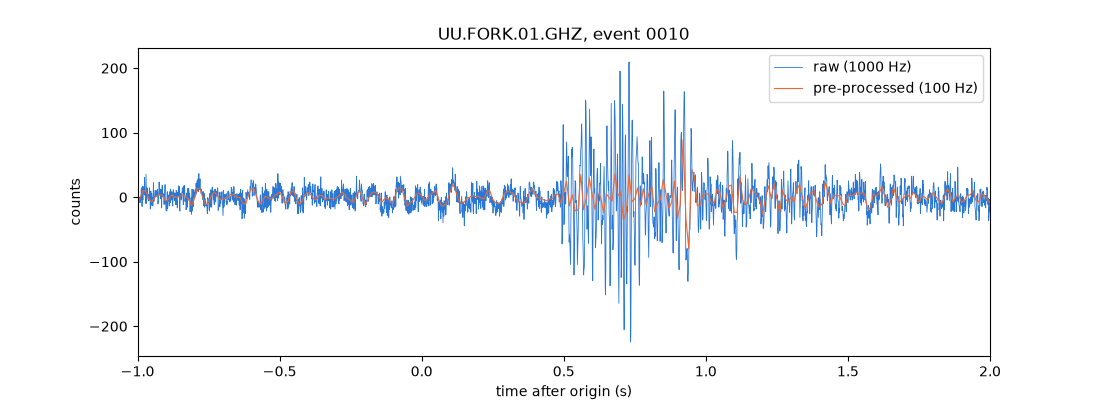

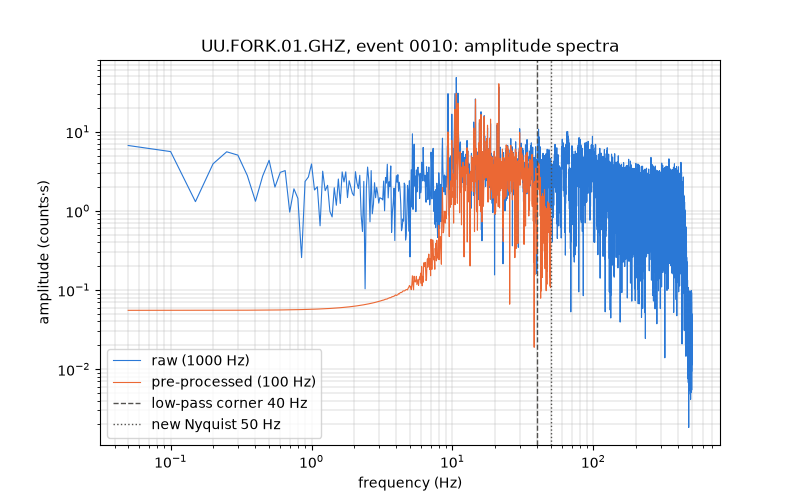

In [64]:
# Compare one component before and after pre-processing: trace (plot 1) and spectrum (plot 2)
sta, comp = "FORK", "Z"                     # station and component to compare

tr_raw = st.select(station=sta, component=comp)[0].copy()
tr_raw.detrend("demean")                    # only remove the offset, so both are centred on 0

tr_pn = st_pn.select(station=sta, component=comp)[0].copy()
tr_pn.trim(tr_raw.stats.starttime, tr_raw.stats.endtime)   # drop the zero padding: same 20 s window

raw_label = f"raw ({tr_raw.stats.sampling_rate:g} Hz)"
pn_label = f"pre-processed ({tr_pn.stats.sampling_rate:g} Hz)"

# --- Plot 1: traces, time after origin ---
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tr_raw.times(reftime=origin), tr_raw.data, color="#2a78d6", lw=0.6, label=raw_label)
ax.plot(tr_pn.times(reftime=origin), tr_pn.data, color="#eb6834", lw=0.8, label=pn_label)
ax.set_xlim(-1, 2)                          # zoom on the arrivals; use (-5, 15) for the whole window
ax.set_xlabel("time after origin (s)")
ax.set_ylabel("counts")
ax.set_title(f"{tr_raw.id}, event {event}")
ax.legend()
plt.show()

# --- Plot 2: amplitude spectra ---
fig, ax = plt.subplots(figsize=(8, 5))
for tr, color, label in [(tr_raw, "#2a78d6", raw_label), (tr_pn, "#eb6834", pn_label)]:
    amp = np.abs(np.fft.rfft(tr.data)) / tr.stats.sampling_rate   # ÷ rate: comparable between rates
    freq = np.fft.rfftfreq(tr.stats.npts, d=tr.stats.delta)       # 0 Hz to Nyquist
    ax.loglog(freq[1:], amp[1:], color=color, lw=0.8, label=label)
ax.axvline(40, color="#52514e", ls="--", lw=1, label="low-pass corner 40 Hz")
ax.axvline(50, color="#52514e", ls=":", lw=1, label="new Nyquist 50 Hz")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("amplitude (counts·s)")
ax.set_title(f"{tr_raw.id}, event {event}: amplitude spectra")
ax.legend()
ax.grid(True, which="both", lw=0.3)
plt.show()



2. PhaseNet for events picking

In [67]:
# 3. PhaseNet model (pretrained ETHZ weights, as Niemz et al.)
model = sbm.PhaseNet.from_pretrained("ethz")

# 4. PhaseNet parameters
params = dict(
    P_threshold=0.1,      # min P probability to make a pick (model default 0.36)
    S_threshold=0.1,      # min S probability to make a pick (model default 0.34)
    blinding=(250, 250),  # ignore 2.5 s at both ends of each 30 s window
    overlap=2500,         # consecutive 30 s windows overlap by 15 s
    stacking="max",       # average overlapping windows
    batch_size=256,       # windows per model call (speed only)
    strict=True,         # missing component → zeros
)

# 5. Run PhaseNet
out = model.classify(st_pn, **params)

# 6. Picks as a table
rows = []
for p in out.picks:
    net, sta, loc = p.trace_id.split(".")[:3]
    rows.append(dict(event_id=event, network=net, station=sta, phase=p.phase,
                     t_rel=round(p.peak_time - origin, 3),   # s after origin (travel time)
                     prob=round(float(p.peak_value), 3)))    # PhaseNet probability
picks = pd.DataFrame(rows).sort_values(["station", "phase"])
picks

,event_id,network,station,phase,t_rel,prob
1,0010,6K,CS03,P,1.040,0.558
2,0010,6K,CS04,S,2.140,0.249
3,0010,6K,CS05,P,1.320,0.766
4,0010,6K,CS05,S,2.610,0.279
0,0010,UU,FOR2,S,1.058,0.394
5,0010,UU,FORU,P,1.013,0.865
6,0010,UU,FORU,S,1.873,0.431
7,0010,UU,FSB2,S,10.328,0.299


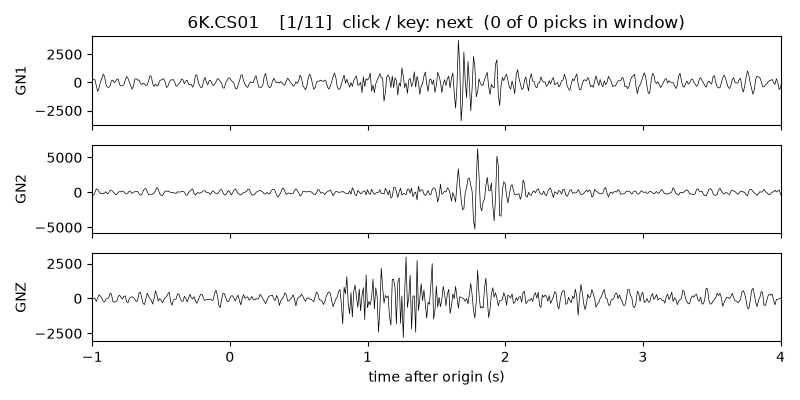

In [68]:
%matplotlib widget
plots.browse_picks(st_pn, picks, origin, tmin=-1, tmax=4, figsize=(8, 4))



# → [Station: CS01 ▾]  plot below; choose another station from the list



In [69]:
# PhaseNet on ALL events, 8 events at a time (8 worker processes)
picks_all, errors = pp.pick_events_parallel(
    cat.index,                 # all 2,900 events
    params,                    # your PhaseNet parameters (thresholds 0.1, overlap 2500, max, strict)
    stations=stations,         # your station selection (minus any you dropped)
    highpass_freq=10,          # 10–40 Hz
    pad="noise",               # noise padding
    n_workers=8,
)
print(len(picks_all), "picks,", picks_all.event_id.nunique(), "events, errors:", errors)

picks_all.to_csv("../data/picks/phasenet_picks_all.csv", index=False)   # save


200/2900 events done, 0 errors
400/2900 events done, 0 errors
600/2900 events done, 0 errors
800/2900 events done, 0 errors
1000/2900 events done, 0 errors
1200/2900 events done, 0 errors
1400/2900 events done, 0 errors
1600/2900 events done, 0 errors
1800/2900 events done, 0 errors
2000/2900 events done, 0 errors
2200/2900 events done, 0 errors
2400/2900 events done, 0 errors
2600/2900 events done, 0 errors
2800/2900 events done, 0 errors
2900/2900 events done, 0 errors
24810 picks, 2762 events, errors: {}


In [71]:
#creating phase.dat file
#*****************************

#full paremeter function:
#pp.create_phase_dat(picks_all, cat,
    #weight="prob",                       # "prob" or "classes"
    #classes=((0.7, 1.0), (0.4, 0.5), (0.2, 0.2), (0.0, 0.1)),   # (min prob, weight), for "classes"
    #t_window=(0.0, 5.0),                 # keep picks 0–5 s after origin
    #min_picks=4, min_stations=3,         # minimum per event, otherwise the event isn't written
    #exclude_events=("0769", "1229", "2228", "2519"),          # suspicious catalog events
    #outfile="../data/input_data/phase.dat")

# Weights = PhaseNet probability
phase = pp.create_phase_dat(picks_all, cat, weight="prob")

Removed 4 events above the datum (0 km a.s.l.): ['2118', '2860', '2866', '2868']
Wrote /rcp/rcp42/home/esotelo/location_project/data/input_data/phase.dat: 1741 events, 18890 picks (P 9526, S 9364), weight = prob; 1021 events not written
